# Description

In this notebook, I will train the CNN model in the FL system.

In [14]:
%cd /content/prune_fl_project

/content/prune_fl_project


In [15]:
!ls

config_celeb.py			       fl_resnet_femnist.ipynb
config_femnist.py		       fl_resnet_prune_celeb.ipynb
fl_cnn_CELEB.ipynb		       fl_resnet_prune_femnist.ipynb
fl_cnn_femnist.ipynb		       fl_sentiment140.ipynb
fl_cnn_prune_CELEB.ipynb	       images
fl_cnn_prune_femnist.ipynb	       model.png
fl_inception_celeb.ipynb	       __pycache__
fl_inception_femnist.ipynb	       README.md
fl_inception_prune_celeb_backup.ipynb  requirements.txt
fl_inception_prune_celeb.ipynb	       sentiment140.ipynb
fl_inception_prune_femnist.ipynb       test.ipynb
fl_resnet_celeb.ipynb		       utils


In [16]:
!pip install -U protobuf

In [17]:
import sys
import tensorflow as tf

print(sys.version)
print(tf.__version__)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
2.21.0


In [19]:
import os

# Must be set before importing TensorFlow/TFF
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"

import tensorflow as tf

tf.random.set_seed(42)

import gc
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.transform import resize
from sklearn.model_selection import train_test_split

# Project imports
from config_femnist import *
from utils.read_data_utils import *

# ---------------------------------------------------------
# IMPORTANT:
# model_utils.py imports tensorflow_federated.
# We don't need TFF from model_utils for the CNN/FedAvg code,
# so load model_utils after temporarily blocking that import.
# ---------------------------------------------------------

import sys

# Temporarily provide a dummy TFF module
class DummyTFF:
    pass

sys.modules["tensorflow_federated"] = DummyTFF()

from utils.model_utils import *
from utils.pruning_utils import *

# Remove dummy module after imports
del sys.modules["tensorflow_federated"]

# ---------------------------------------------------------
# GPU check
# ---------------------------------------------------------

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU available:", gpus)
    except RuntimeError as e:
        print(e)
else:
    print("No GPU detected")

print("TensorFlow version:", tf.__version__)
print("Imports successful!")

No GPU detected
TensorFlow version: 2.21.0
Imports successful!


In [20]:
# =========================================================
# Dataset Hyper-parameter
DATASET_NAME = 'mnist'

IMAGE_DIMENSION = 28
INPUT_SHAPE = (IMAGE_DIMENSION, IMAGE_DIMENSION, 1)

OUPUT_SHAPE = 62


# =========================================================
# Model Hyper-parameter
OPTIMIZER = 'adam'
LOSS = 'categorical_crossentropy'
METRICS = ['accuracy']

LIST_NUMBER_FILTERS = [32, 64]
FILTER_SIZE = 5

MODEL_TYPE = "vanilla_conv"

PATH_GLOBAL_MODEL = os.path.join(
    "models",
    "global_model_femnist.h5"
)


# =========================================================
# Training Hyper-parameter
# Small test configuration
NUM_ROUNDS = 5
NUM_SELECTED_CLIENT = 3

LOCAL_EPOCHS = 1
LOCAL_BATCH_SIZE = 32


# =========================================================
# Pruning Hyper-parameter
# Pruning will NOT be used for this baseline
MAX_PRUNED_ROUND = 0
IS_STILL_PRUNE = False

PRUNE_PATIENCE = 0
MAX_PRUNE_PATIENCE = 3

STD_THRESHOLD_PRUNE = 2.0

# 1. Dataset

## 1.1. Load dataset

In [35]:
%pip install -q datasets

from datasets import load_dataset
from collections import defaultdict
import numpy as np
import tensorflow as tf

femnist = load_dataset("flwrlabs/femnist", split="train")

writer_indices = defaultdict(list)

for i, writer_id in enumerate(femnist["writer_id"]):
    writer_indices[writer_id].append(i)

rng = np.random.default_rng(42)

train_indices = {}
test_indices = {}

for writer_id, indices in writer_indices.items():
    indices = rng.permutation(indices)

    if len(indices) > 1:
        n_test = max(1, int(0.2 * len(indices)))

        test_indices[writer_id] = indices[:n_test].tolist()
        train_indices[writer_id] = indices[n_test:].tolist()
    else:
        train_indices[writer_id] = indices.tolist()


class FEMNISTSplit:

    def __init__(self, dataset, client_indices):
        self.dataset = dataset
        self.client_indices = client_indices
        self.client_ids = list(client_indices.keys())

    def create_tf_dataset_for_client(self, client_id):

        indices = self.client_indices[client_id]

        images = np.stack([
            np.asarray(
                self.dataset[int(i)]["image"].convert("L"),
                dtype=np.uint8
            )
            for i in indices
        ])

        labels = np.array([
            self.dataset[int(i)]["character"]
            for i in indices
        ], dtype=np.int64)

        return tf.data.Dataset.from_tensor_slices({
            "pixels": images,
            "label": labels
        })


emnist_train = FEMNISTSplit(femnist, train_indices)
emnist_test = FEMNISTSplit(femnist, test_indices)

print("Training clients:", len(emnist_train.client_ids))
print("Testing clients:", len(emnist_test.client_ids))

README.md:   0%|          | 0.00/6.09k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  201MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/814277 [00:00<?, ? examples/s]

Training clients: 3597
Testing clients: 3597


In [36]:
num_clients = len(emnist_train.client_ids)

print(f"Number of clients: {num_clients}")

list_num_samples = []

for client_id in emnist_train.client_ids:
    client_dataset = emnist_train.create_tf_dataset_for_client(client_id)
    num_samples = sum(1 for _ in client_dataset)
    list_num_samples.append(num_samples)

list_num_samples = np.array(list_num_samples)

print(f"Total number of samples in training set: {list_num_samples.sum()}")
print(f"Average number of samples per client: {list_num_samples.mean()}")



Number of clients: 3597
Total number of samples in training set: 652853
Average number of samples per client: 181.4993049763692


## 1.2. Prepare training dataset

In [37]:
list_clients_data = Create_Clients_Data(emnist_train, DATASET_NAME)
print(f"Number of user: {len(list_clients_data)}")

Number of user: 3597


Number of client: 3597


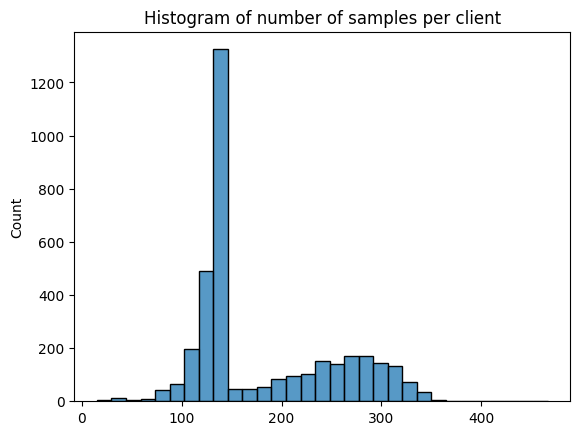

In [38]:
list_num_samples = []

for client_data in list_clients_data:
    list_X = client_data['list_X']
    list_num_samples.append(len(list_X))

print(f"Number of client: {len(list_num_samples)}")
plt.title("Histogram of number of samples per client")
sns.histplot(list_num_samples)
plt.show();

Shape of image: (28, 28, 1)
Client name= f0020_08
Label = [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


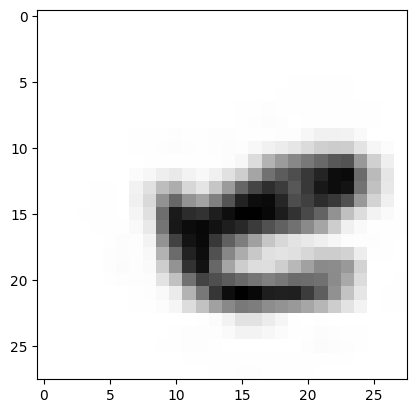

In [39]:
idx_client = idx_sample = np.random.randint(0, 50)

client_data = list_clients_data[idx_client]

client_name = client_data['client_name']
list_X = client_data['list_X']
list_y = client_data['list_y']

X = list_X[idx_sample]
print(f"Shape of image: {X.shape}")
y = list_y[idx_sample]

print(f"Client name= {client_name}")
print(f"Label = {y}")
plt.imshow(X, cmap='gray')
plt.show();

## 1.3. Prepare val - test dataset

In [40]:
list_data_test = Create_Clients_Data(emnist_test)

X_test = []
y_test = []
for data_test in list_data_test:
    X_test.append(data_test['list_X'])
    y_test.append(data_test['list_y'])
X_test = np.concatenate(X_test)
y_test = np.concatenate(y_test)

X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

print(f"Shape of X val: {X_val.shape}")
print(f"Shape of y val: {y_val.shape}")

print(f"Shape of X test: {X_test.shape}")
print(f"Shape of y test: {y_test.shape}")

Shape of X val: (80712, 28, 28, 1)
Shape of y val: (80712, 62)
Shape of X test: (80712, 28, 28, 1)
Shape of y test: (80712, 62)


# 2. Training FL

In [41]:
def Define_Simple_CNN_Model(input_shape, output_shape, list_number_filters, kernel_size = 5, max_pooling_step=2, model_name=None):
    """
    This function create the simple CNN model.
    """

    model = models.Sequential(name=model_name)
    model.add(Input(input_shape))

    for (idx_filter, number_filter) in enumerate(list_number_filters):
        model.add(Conv2D(number_filter, (kernel_size, kernel_size), name=f'prunable_conv_{idx_filter}'))
        # model.add(BatchNormalization())
        model.add(Activation("relu"))
        model.add(MaxPooling2D(pool_size=max_pooling_step, strides=max_pooling_step))

    # model.add(layers.Flatten())
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(output_shape, activation='softmax', name='classifier'))
    return model


In [42]:
keras.backend.clear_session()
global_model = Define_Simple_CNN_Model(input_shape=INPUT_SHAPE, output_shape=OUPUT_SHAPE,\
                            list_number_filters=LIST_NUMBER_FILTERS, model_name="global_model")

# global_model = Get_Model(MODEL_TYPE, INPUT_SHAPE, OUPUT_SHAPE, LIST_NUMBER_FILTERS, model_name="global_model")
global_model.compile(optimizer=OPTIMIZER, loss=LOSS, metrics = METRICS)
global_model.summary()
plot_model(global_model, to_file=os.path.join('images', f'model_architecture_{DATASET_NAME}.png'), show_shapes=True, show_layer_names=True);
global_model.save(PATH_GLOBAL_MODEL)

Model: "global_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ prunable_conv_0 (Conv2D)        │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prunable_conv_1 (Conv2D)        │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 62)             │         4,030 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,126 (219.24 KB)

 Trainable params: 56,126 (219.24 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
NUM_CLIENTS = num_clients
list_val_acc = []
list_val_loss = []


for idx_round in range(NUM_ROUNDS):
    print("\n [INFO] Round {}".format(idx_round))

    global_model = tf.keras.models.load_model(PATH_GLOBAL_MODEL)
    global_model.compile(optimizer=OPTIMIZER, loss=LOSS, metrics = METRICS)

    client_model = keras.models.clone_model(global_model)
    client_model.compile(optimizer=OPTIMIZER, loss=LOSS, metrics=METRICS)

    # Select random subset of clients
    # selected_percent_client = np.random.uniform(0.0, MAX_SELECTED_PERCENT_CLIENT)
    # num_selected_clients = max(int(NUM_CLIENTS * selected_percent_client), 1)
    num_selected_clients = NUM_SELECTED_CLIENT
    selected_clients_data = random.sample(list_clients_data, num_selected_clients)

    # Loop through selected client
    list_client_model_weight = []
    list_client_scales = []
    for selectd_client_data in selected_clients_data:
        client_model.set_weights(global_model.get_weights())  # Clone global model

        list_X = selectd_client_data['list_X']
        list_y = selectd_client_data['list_y']
        client_model.fit(list_X, list_y, epochs=LOCAL_EPOCHS, batch_size=LOCAL_BATCH_SIZE, verbose=0)

        list_client_model_weight.append(client_model.get_weights())    # store local weight for update global model later.
        list_client_scales.append(len(list_X))

    # Calculate scale of each client
    list_client_scales = np.array(list_client_scales)
    list_client_scales = list_client_scales / list_client_scales.sum()

    # Update the global model weights
    avg_weights = FedAvg(global_model, list_client_model_weight, list_client_scales)
    global_model.set_weights(avg_weights)

    # Evaluate model on validation data
    if idx_round % 2 == 0:
        val_loss, val_acc = global_model.evaluate(X_val, y_val, verbose=0)
        print(f'Val loss: {val_loss}, Val accuracy: {val_acc}')
        list_val_acc.append(val_acc)
        list_val_loss.append(val_loss)

    global_model.save(PATH_GLOBAL_MODEL)
    keras.backend.clear_session()

    selected_clients_data = None
    list_client_model_weight = list_client_scales = None
    gc.collect()


 [INFO] Round 0


Val loss: 3.842066526412964, Val accuracy: 0.020715631544589996



 [INFO] Round 1



 [INFO] Round 2


Val loss: 3.722994327545166, Val accuracy: 0.09436019510030746



 [INFO] Round 3



 [INFO] Round 4


Val loss: 3.6436028480529785, Val accuracy: 0.11858212202787399


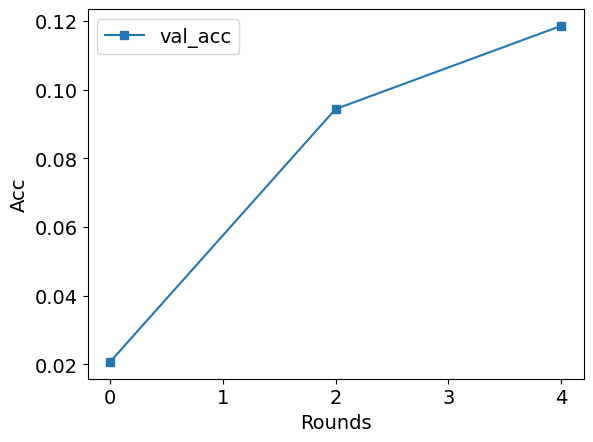

In [49]:
# Sample data arrays
list_rounds = np.arange(0, NUM_ROUNDS, 2)

plt.rcParams.update({'font.size': 14})

plt.plot(list_rounds, list_val_acc, label='val_acc', marker='s')
plt.xlabel('Rounds')
plt.ylabel('Acc')

plt.legend()
plt.show()

# 3. Evaluation

In [45]:
# X_test = np.array([resize(image, (IMAGE_DIMENSION, IMAGE_DIMENSION)) for image in X_test])
print(f"Shape of X test: {X_test.shape}")
print(f"Shape of y test: {y_test.shape}")

Shape of X test: (80712, 28, 28, 1)
Shape of y test: (80712, 62)


In [46]:
# Evaluate model on testing data
val_loss, val_acc = global_model.evaluate(X_test, y_test, verbose=0)
print(f'Val loss: {val_loss}, Val accuracy: {val_acc}')

Val loss: 3.8741841316223145, Val accuracy: 0.07151352614164352
